A project on Exploratory Data Analysis

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/ecommerce_reviews_classification.csv")
df.head()

,review_id,rating_dup,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,R90000,5.0,20105.0,positive,125.0,5.0,Good roduct,No,1033.0
1,R90001,5.0,NaN,positive,80.0,5.0,Terrible quality,No,1080.0
2,R90002,4.0,20356.0,positive,21.0,4.0,NaN,No,1074.0
3,R90003,5.0,20007.0,positive,189.0,5.0,Excellent!,Yes,1092.0
4,R90004,5.0,20261.0,positive,55.0,5.0,Not as expected,Yes,1033.0


Duplicate Observation

In [ ]:
print(df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(265, 9)
review_id            14
rating_dup            9
user_id              13
sentiment            13
helpful_votes        17
rating                9
review_text          20
verified_purchase    19
product_id           12
dtype: int64
Duplicates: 15


Removing duplicates

In [ ]:
df = df.drop_duplicates()
print(df.shape)

(250, 9)


In [ ]:
new_ids = np.char.add("R9", np.char.zfill(df.index.values.astype(str), 4))
df["review_id"] = np.where(df["review_id"].isnull(), new_ids, df["review_id"])

In [ ]:
df = df.drop(columns=["rating_dup"])

In [ ]:
df["verified_purchase"] = df["verified_purchase"].str.lower().map({
    "yes": "Yes", "ye": "Yes", "ys": "Yes", "es": "Yes",
    "no": "No", "n": "No", "o": "No"
})
df["verified_purchase"] = df["verified_purchase"].fillna("Unknown")
print(df["verified_purchase"].value_counts())

verified_purchase
Yes        164
No          69
Unknown     17
Name: count, dtype: int64


Fixing in consistent Data

In [ ]:
import difflib

correct = ["good product", "value for money", "excellent!",
           "would buy again", "not as expected", "terrible quality"]

def fix_text(text):
    if pd.isnull(text):
        return "No review"
    match = difflib.get_close_matches(text.lower(), correct, n=1, cutoff=0.8)
    return match[0].capitalize() if match else "No review"

df["review_text"] = df["review_text"].apply(fix_text)
print(df["review_text"].value_counts())

review_text
Terrible quality    46
Value for money     43
Not as expected     40
Excellent!          38
Would buy again     33
Good product        30
No review           20
Name: count, dtype: int64


In [ ]:
# sentiment from rating
def get_sentiment(r):
    if r <= 2:
        return "negative"
    elif r == 3:
        return "neutral"
    else:
        return "positive"

mask = df["sentiment"].isnull() & df["rating"].notnull()
df.loc[mask, "sentiment"] = df.loc[mask, "rating"].apply(get_sentiment)

# rating from sentiment
df["rating"] = df["rating"].fillna(df["sentiment"].map({"negative": 1, "neutral": 3, "positive": 5}))

Filling missing Values

In [ ]:
df["helpful_votes"] = df["helpful_votes"].fillna(df["helpful_votes"].median())
df = df.fillna({"user_id": 0, "product_id": 0})

In [ ]:
df["rating"] = df["rating"].astype(int)
df["helpful_votes"] = df["helpful_votes"].astype(int)
df["user_id"] = df["user_id"].astype(int)
df["product_id"] = df["product_id"].astype(int)

Generating csv file

In [ ]:
print(df.isnull().sum())
print(df.shape)
df.to_csv("cleaned_reviews.csv", index=False)
df.head()

review_id            0
user_id              0
sentiment            0
helpful_votes        0
rating               0
review_text          0
verified_purchase    0
product_id           0
dtype: int64
(250, 8)


,review_id,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,R90000,20105,positive,125,5,Good product,No,1033
1,R90001,0,positive,80,5,Terrible quality,No,1080
2,R90002,20356,positive,21,4,No review,No,1074
3,R90003,20007,positive,189,5,Excellent!,Yes,1092
4,R90004,20261,positive,55,5,Not as expected,Yes,1033


checking for outliers

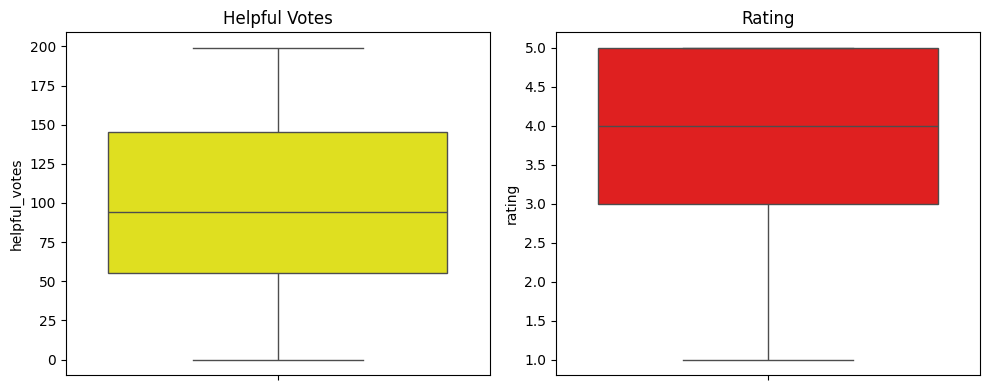

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(y=df["helpful_votes"], color="yellow")
plt.title("Helpful Votes")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["rating"], color="red")
plt.title("Rating")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/cleaned_reviews.csv")

univariate analysis

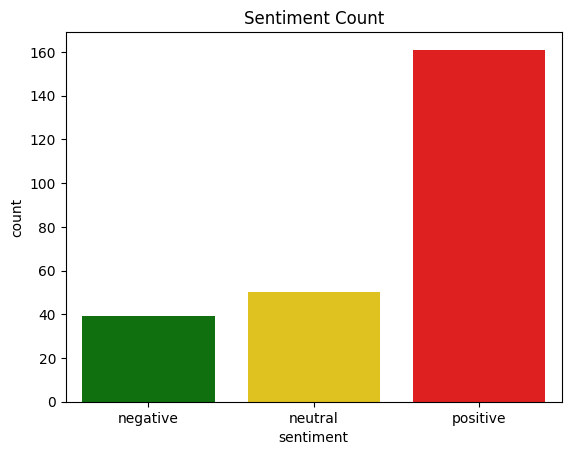

In [ ]:
sns.countplot(x="sentiment", data=df, hue="sentiment",
              order=["negative", "neutral", "positive"],
              palette=["red", "gold", "green"], legend=False)
plt.title("Sentiment Count")
plt.show()

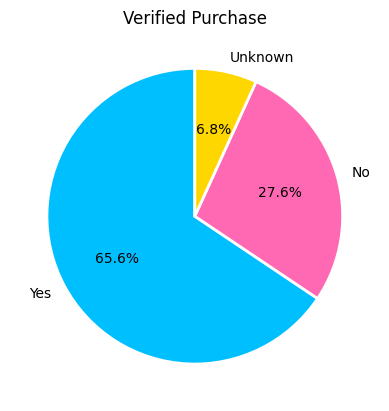

In [ ]:
df["verified_purchase"].value_counts().plot.pie(
    autopct="%1.1f%%", colors=["deepskyblue", "hotpink", "gold"],
    startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
plt.title("Verified Purchase")
plt.ylabel("")
plt.show()

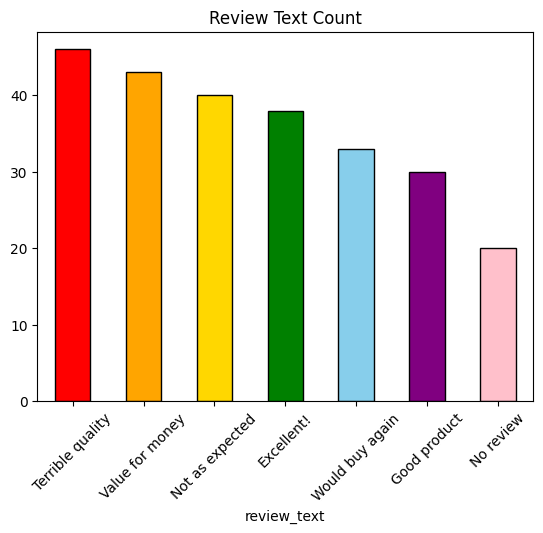

In [ ]:
df["review_text"].value_counts().plot.bar(
    color=["red", "orange", "gold", "green", "skyblue", "purple", "pink"],
    edgecolor="black")
plt.title("Review Text Count")
plt.xticks(rotation=45)
plt.show()

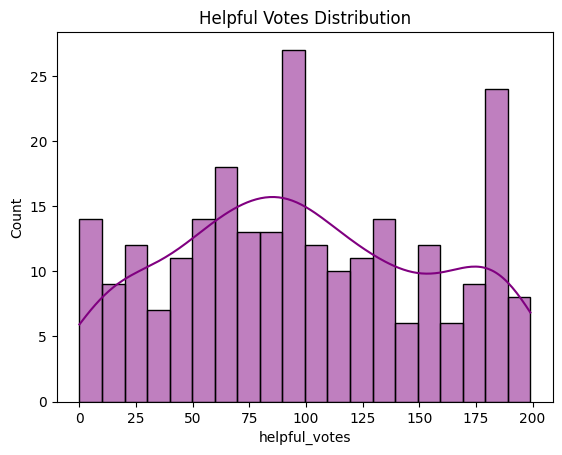

In [ ]:
sns.histplot(df["helpful_votes"], bins=20, kde=True, color="purple")
plt.title("Helpful Votes Distribution")
plt.show()


In [ ]:
bivariate analysis

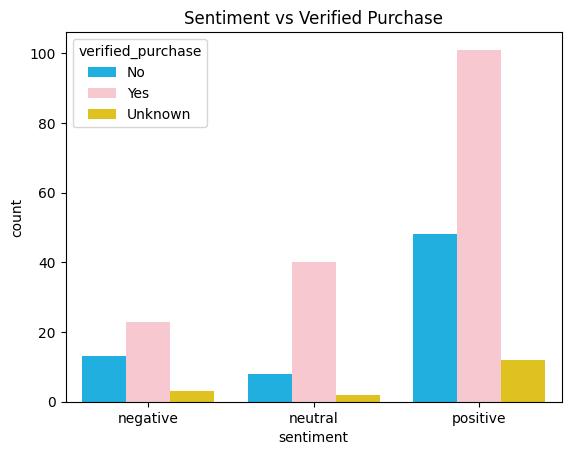

In [ ]:
sns.countplot(x="sentiment", hue="verified_purchase", data=df,
              order=["negative", "neutral", "positive"],
              palette=["deepskyblue", "pink", "gold"])
plt.title("Sentiment vs Verified Purchase")
plt.show()

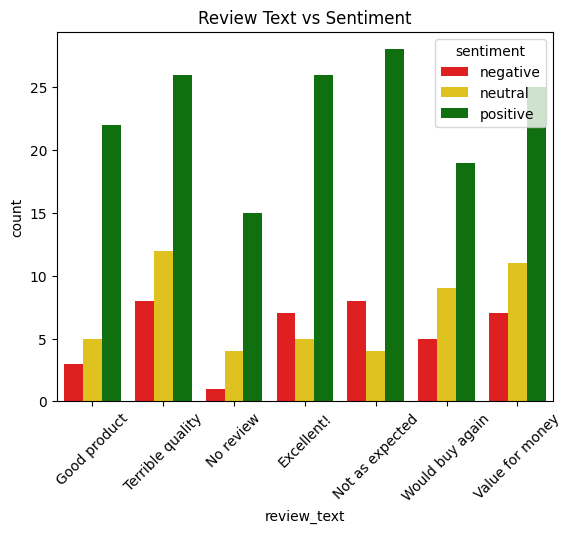

In [ ]:
sns.countplot(x="review_text", hue="sentiment", data=df,
              hue_order=["negative", "neutral", "positive"],
              palette=["red", "gold", "green"])
plt.xticks(rotation=45)
plt.title("Review Text vs Sentiment")
plt.show()

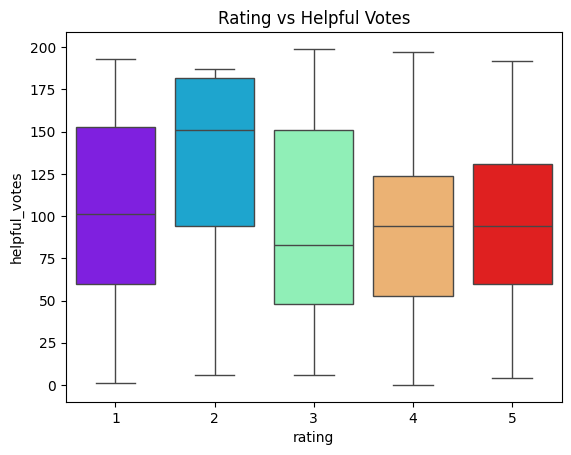

In [ ]:
sns.boxplot(x="rating", y="helpful_votes", data=df, hue="rating",
            palette="rainbow", legend=False)
plt.title("Rating vs Helpful Votes")
plt.show()

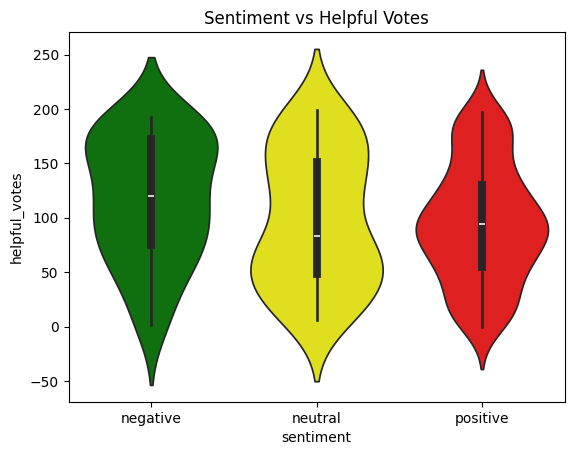

In [ ]:
sns.violinplot(x="sentiment", y="helpful_votes", data=df, hue="sentiment",
               order=["negative", "neutral", "positive"],
               palette=["red", "yellow", "green"], legend=False)
plt.title("Sentiment vs Helpful Votes")
plt.show()

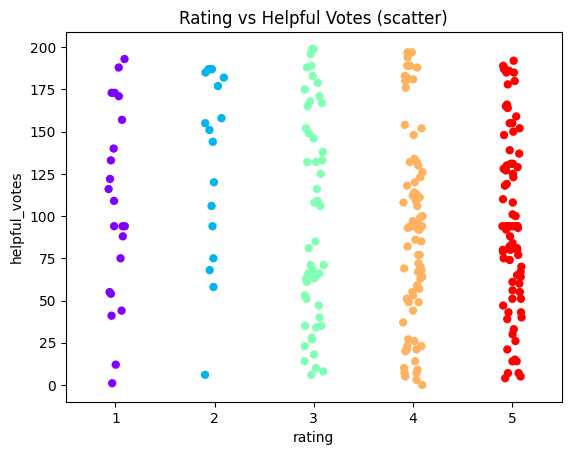

In [ ]:
sns.stripplot(x="rating", y="helpful_votes", data=df, hue="rating",
              palette="rainbow", size=6, legend=False)
plt.title("Rating vs Helpful Votes (scatter)")
plt.show()

multivariate analysis

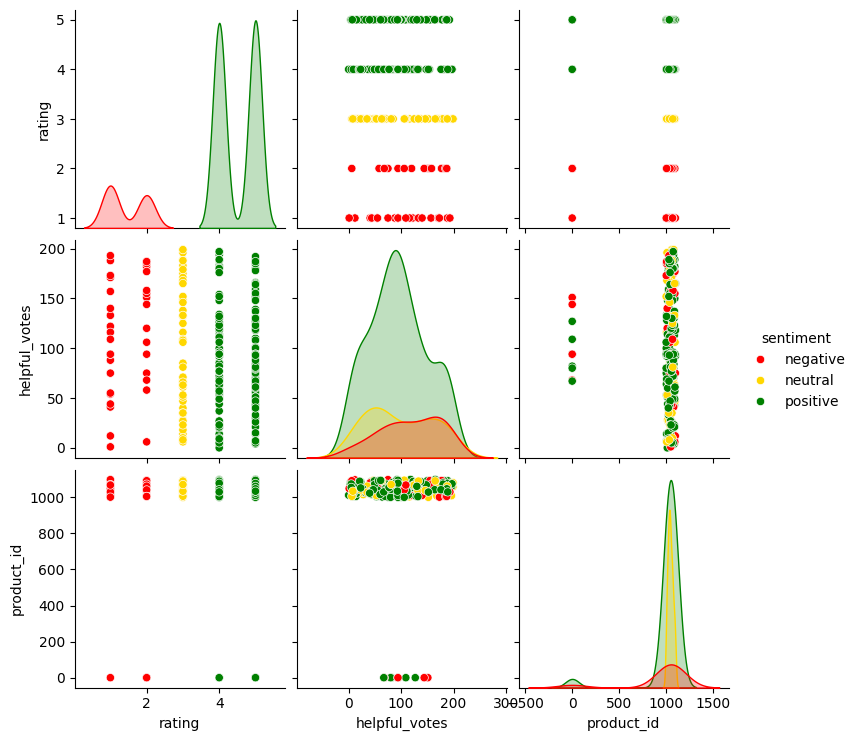

In [ ]:
sns.pairplot(df[["rating", "helpful_votes", "product_id", "sentiment"]],
             hue="sentiment", hue_order=["negative", "neutral", "positive"],
             palette=["red", "gold", "green"])
plt.show()

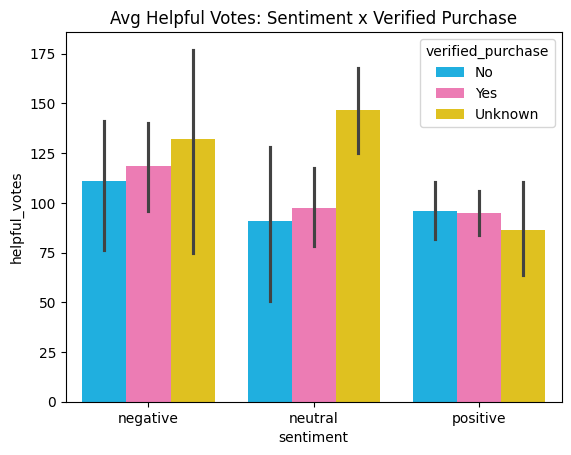

In [ ]:
sns.barplot(x="sentiment", y="helpful_votes", hue="verified_purchase", data=df,
            order=["negative", "neutral", "positive"],
            palette=["deepskyblue", "hotpink", "gold"])
plt.title("Avg Helpful Votes: Sentiment x Verified Purchase")
plt.show()


Final Analysis: Key Insights

Of 250 cleaned reviews, 66% came from verified purchases. Negative reviews earned the most helpful votes, averaging 117 versus 94 for positive ones, though rating and votes are only weakly correlated (-0.10). The most common review phrase was “Terrible quality,” frequently appearing on positive ratings, showing the text is unreliable